# Пошаговый разбор: от сырых данных Apple Watch до предсказания стадии сна

Ноутбук повторяет **ровно тот код**, которым статья (Walch et al., SLEEP 2019) строит признаки, и показывает
промежуточные сигналы на одном испытуемом. Перед запуском должен быть выполнен препроцессинг
(`source/preprocessing/preprocessing_runner.py`, конфигурация «1. Preprocessing» в VS Code).

Ядро: `.venv` проекта. Рабочая папка — корень репозитория.

In [1]:
%matplotlib inline
import os, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'source').exists() else Path.cwd().parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / 'repro')]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
import sleeplib as sl
plt.rcParams['figure.figsize'] = (13, 3.2); plt.rcParams['axes.grid'] = True
SUBJECT = '8686948'
print(ROOT)

C:\Users\Repo\sleep_classifiers


## 1. Сырые файлы
Время — **секунды от начала PSG**. Ускорение в g (с гравитацией), ЧСС — нерегулярно, метки — по 30 с.

In [2]:
motion = pd.read_csv(f'data/motion/{SUBJECT}_acceleration.txt', sep=' ', header=None, names=['t','x','y','z'])
hr = pd.read_csv(f'data/heart_rate/{SUBJECT}_heartrate.txt', header=None, names=['t','bpm'])
labels = pd.read_csv(f'data/labels/{SUBJECT}_labeled_sleep.txt', sep=' ', header=None, names=['t','stage'])
steps = pd.read_csv(f'data/steps/{SUBJECT}_steps.txt', header=None, names=['t','steps'])
for name, df in [('motion', motion), ('hr', hr), ('labels', labels), ('steps', steps)]:
    print(f'{name:7s} rows={len(df):8d}  t: {df.t.min()/3600:8.1f} .. {df.t.max()/3600:6.1f} ч')
labels.stage.value_counts().sort_index()

motion  rows= 1535000  t:     -0.3 ..    8.3 ч
hr      rows=    6669  t:   -168.0 ..    8.3 ч
labels  rows=     971  t:      0.0 ..    8.1 ч
steps   rows=    1058  t:   -168.0 ..    8.2 ч


stage
-1     16
 0     49
 1     68
 2    508
 3    171
 5    159
Name: count, dtype: int64

## 2. Обрезка: пересечение интервалов motion ∩ HR ∩ PSG
`RawDataProcessor.crop_all` оставляет только ночь, где есть все три сигнала (файлы `outputs/cropped/`).

In [3]:
cm = pd.read_csv(f'outputs/cropped/{SUBJECT}_cleaned_motion.out', sep=' ', header=None, names=['t','x','y','z'])
ch = pd.read_csv(f'outputs/cropped/{SUBJECT}_cleaned_hr.out', sep=' ', header=None, names=['t','bpm'])
print('motion', cm.t.min(), cm.t.max(), ' hr', ch.t.min(), ch.t.max())
print('частота ускорения ~', round(1/np.median(np.diff(cm.t)), 1), 'Гц; ЧСС раз в', np.median(np.diff(ch.t)), 'с')

motion 0.011899 29099.989272  hr 1.51231 29099.49779
частота ускорения ~ 49.9 Гц; ЧСС раз в 5.0 с


## 3. Activity counts (эмуляция актиграфа, te Lindert & Van Someren 2013)
`ActivityCountService.build_activity_counts_without_matlab`: используется **только ось z** →
ресемплинг на 50 Гц → полосовой фильтр 3–11 Гц → |·| → 128 уровней на 0–5 g → максимум за секунду →
сумма за 15 с → `(x − 18)·3.07`, обрезка снизу нулём.

совпадает с файлом пайплайна: True


Text(0.5, 0, 'часы')

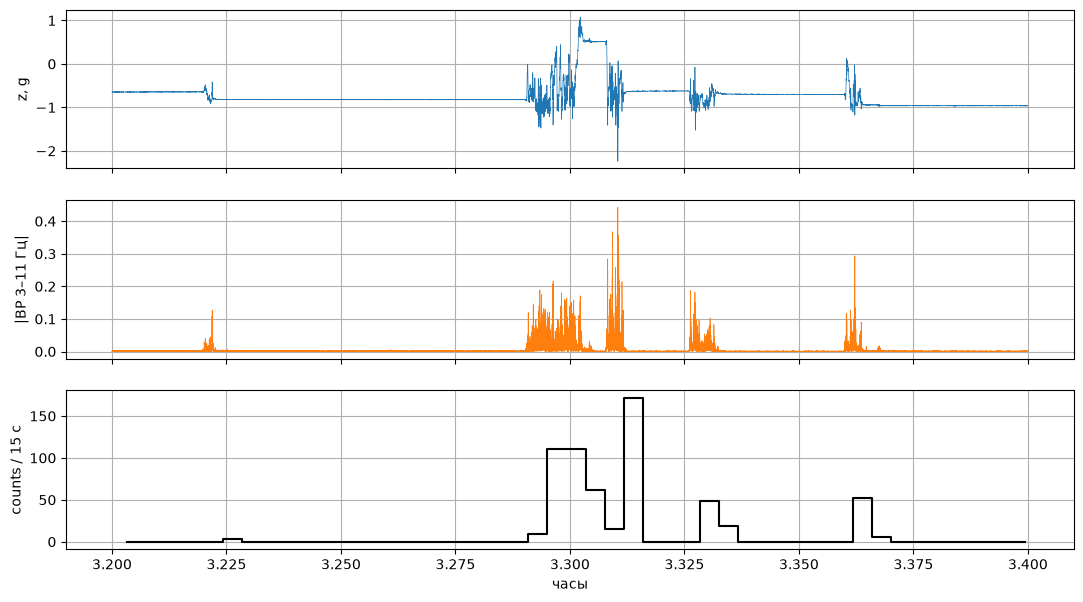

In [4]:
fs = 50
d = cm.values
t = np.arange(d[:,0].min(), d[:,0].max(), 1/fs)
z = np.interp(t, d[:,0], d[:,3])
b, a = butter(5, [3/(fs/2), 11/(fs/2)], 'bandpass')
zf = np.abs(filtfilt(b, a, z))
binned = np.digitize(zf, np.linspace(0, 5, 129))
sec = binned[:len(binned)//fs*fs].reshape(-1, fs).max(1)
counts = sec[:len(sec)//15*15].reshape(-1, 15).sum(1)
counts = np.clip((counts - 18) * 3.07, 0, None)
ref = pd.read_csv(f'outputs/cropped/{SUBJECT}_cleaned_counts.out', header=None).values
print('совпадает с файлом пайплайна:', np.allclose(counts, ref[:,1]))
win = slice(int(3.2*3600*fs), int(3.4*3600*fs))
fig, ax = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
ax[0].plot(t[win]/3600, z[win], lw=.5); ax[0].set_ylabel('z, g')
ax[1].plot(t[win]/3600, zf[win], lw=.5, c='C1'); ax[1].set_ylabel('|BP 3–11 Гц|')
tc = ref[:,0]; m = (tc>=3.2*3600)&(tc<=3.4*3600)
ax[2].step(tc[m]/3600, ref[m,1], where='post', c='k'); ax[2].set_ylabel('counts / 15 с'); ax[2].set_xlabel('часы')

## 4. Признак `motion` на эпоху
Для каждой 30-с эпохи берётся окно ±285 с (≈10 мин), counts интерполируются на 1 Гц и усредняются с
гауссовым весом σ = 50 с вокруг центра окна (`ActivityCountFeatureService`, `utils.smooth_gauss`).

Text(0.5, 0, 'часы от первой валидной эпохи')

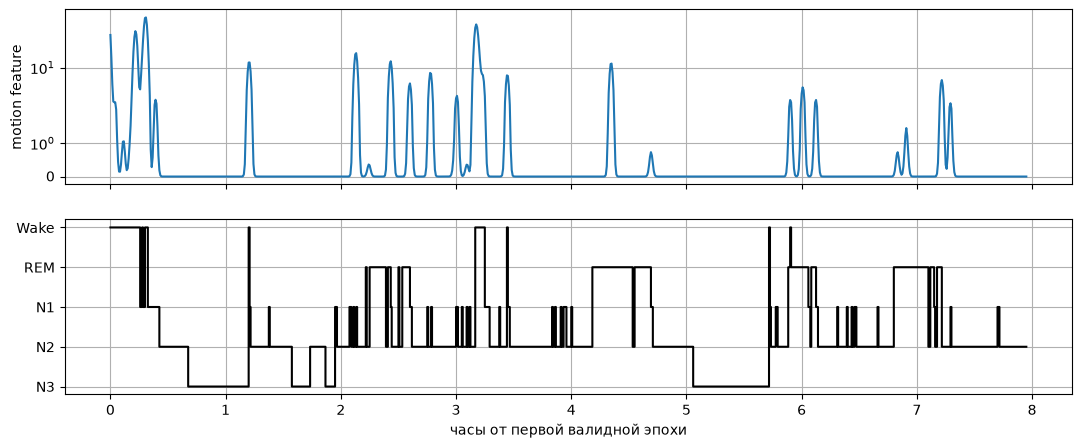

In [5]:
feat = sl.load_paper_features([SUBJECT])[SUBJECT]
th = np.arange(len(feat['stage'])) * 0.5 / 60
fig, ax = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
ax[0].plot(th, feat['motion'], c='C0'); ax[0].set_ylabel('motion feature'); ax[0].set_yscale('symlog')
order = {0: 4, 5: 3, 1: 2, 2: 1, 3: 0, 4: 0}
ax[1].step(th, [order[int(s)] for s in feat['stage']], where='post', c='k')
ax[1].set_yticks([0,1,2,3,4], ['N3','N2','N1','REM','Wake']); ax[1].set_xlabel('часы от первой валидной эпохи')

## 5. Признак `hr`: локальная вариабельность ЧСС
`HeartRateFeatureService`: ЧСС → интерполяция на 1 Гц → вычитание среднего → свёртка с «разностью гауссиан»
(σ1 = 120 с, σ2 = 600 с, вес 0.75, ядро длиной 285 отсчётов) → деление на 90-й перцентиль |·| →
**стандартное отклонение в окне ±285 с**. То есть модель видит не уровень пульса, а то, насколько он «скачет».

Замечание: ядро имеет длину всего 285 с, поэтому гауссиана с σ = 600 с внутри него почти плоская —
фактически фильтр = узкая гауссиана σ = 120 с минус константа (≈ сглаживание + удаление тренда).

Text(0, 0.5, 'hr feature (std в окне)')

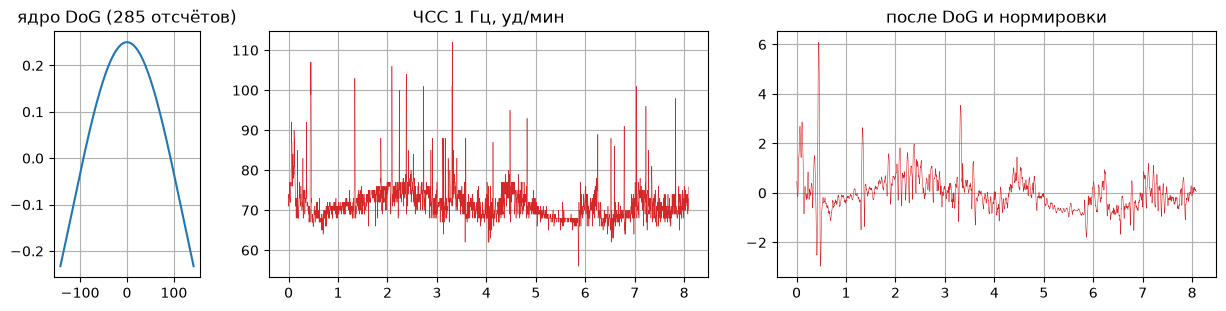

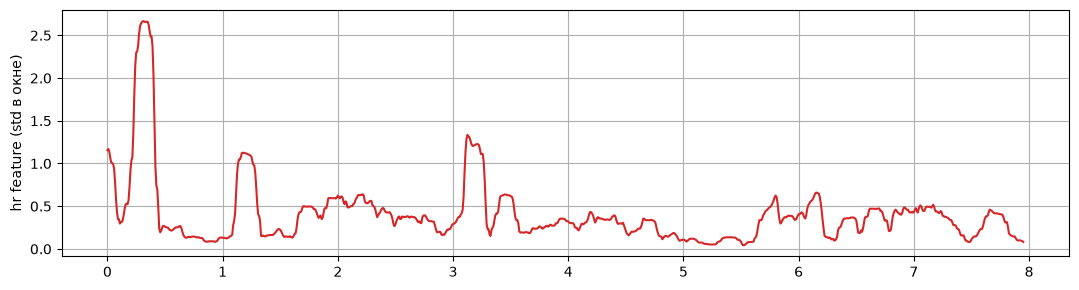

In [6]:
from source import utils
ti = np.arange(ch.t.min(), ch.t.max(), 1)
hi = np.interp(ti, ch.t, ch.bpm)
dog = utils.convolve_with_dog(hi, 285)
dog = dog / np.percentile(np.abs(dog), 90)
k = np.arange(285); mu = 142
kernel = np.exp(-.5*((k-mu)/120)**2) - .75*np.exp(-.5*((k-mu)/600)**2)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2), gridspec_kw=dict(width_ratios=[1, 3, 3]))
ax[0].plot(k - mu, kernel); ax[0].set_title('ядро DoG (285 отсчётов)')
ax[1].plot(ti/3600, hi, lw=.4, c='C3'); ax[1].set_title('ЧСС 1 Гц, уд/мин')
ax[2].plot(ti[:len(dog)]/3600, dog[:len(ti)], lw=.4, c='C3'); ax[2].set_title('после DoG и нормировки')
plt.figure(); plt.plot(th, feat['hr'], c='C3'); plt.ylabel('hr feature (std в окне)')

## 6. «Clock proxy»: модель циркадных часов
Шаги за неделю → «средний день» (бины 10 мин) → оценка освещённости (если ≥ 20 шагов: 50/500/1000 люкс по
времени суток) → драйв света α(I) = 0.16·(I/9500)^0.6 → 60 дней интегрирования осциллятора Forger 1999
(RK4, шаг 0.1 ч), с момента начала PSG — темнота. Признак = x(t), нормированный к 0 в начале ночи и к 1 в
минимуме x (≈ минимум температуры тела). В открытых данных нет времени суток → допущение «начало PSG = 23:00».

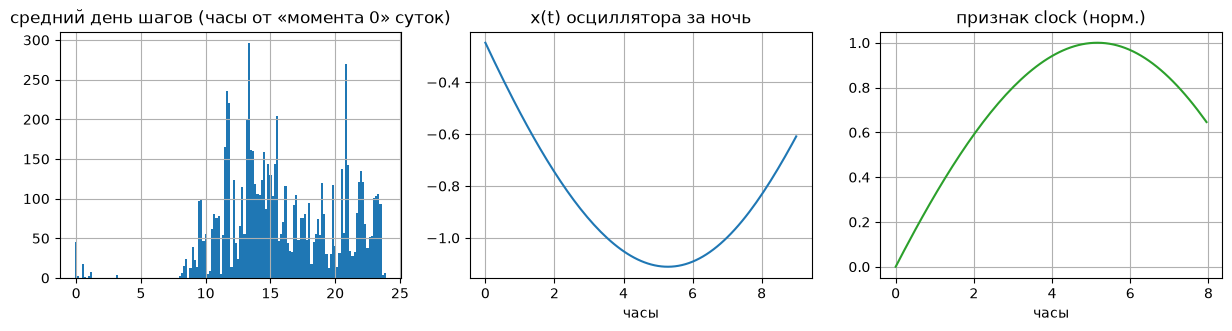

In [7]:
avg = steps.copy(); avg['bin'] = ((avg.t % 86400) // 600).astype(int)
prof = avg.groupby('bin').steps.mean()
clock = np.loadtxt(f'data/circadian_predictions/{SUBJECT}_clock_proxy.txt', delimiter=',')
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
ax[0].bar(prof.index*10/60, prof.values, width=10/60); ax[0].set_title('средний день шагов (часы от «момента 0» суток)')
ax[1].plot((clock[:,0]-clock[0,0])/3600, clock[:,1]); ax[1].set_title('x(t) осциллятора за ночь')
ax[2].plot(th, feat['clock'], c='C2'); ax[2].set_title('признак clock (норм.)')
for a in ax[1:]: a.set_xlabel('часы')

## 7. Модель статьи: LOSO на трёх признаках
Обучаем на 30 людях, проверяем на 31-м — и так для каждого. Метрики как в Таблицах 2–5: порог подбирается так,
чтобы доля верно распознанного сна = 0.9 / 0.93, и смотрим долю верно распознанного бодрствования.

In [8]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from joblib import Parallel, delayed
data = sl.load_paper_features()
F = ['motion', 'hr', 'clock']
def fold(test):
    X, y, _ = sl.stack(data, [s for s in sl.SUBJECTS if s != test], F)
    m = make_pipeline(StandardScaler(), MLPClassifier((15, 15, 15), alpha=0.01, max_iter=2000, n_iter_no_change=20, random_state=0))
    m.fit(X, sl.sleep_wake(y))
    return m.predict_proba(sl.stack(data, [test], F)[0])[:, 1]
p = np.concatenate(Parallel(n_jobs=-1, prefer="threads")(delayed(fold)(s) for s in sl.SUBJECTS))
y = sl.sleep_wake(np.concatenate([data[s]['stage'] for s in sl.SUBJECTS]))
pd.Series(sl.sw_summary(y, p)).round(3)

auc                0.864
wake_correct@80    0.796
accuracy@80        0.800
kappa@80           0.315
wake_correct@90    0.677
accuracy@90        0.881
kappa@90           0.429
wake_correct@93    0.607
accuracy@93        0.903
kappa@93           0.460
wake_correct@95    0.555
accuracy@95        0.917
kappa@95           0.484
dtype: float64

## 8. Что модель «думает»: SHAP
LightGBM на тех же трёх признаках; значения SHAP в log-odds сна. Положительные — толкают к «сну».

C:\Users\Repo\sleep_classifiers\.venv\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


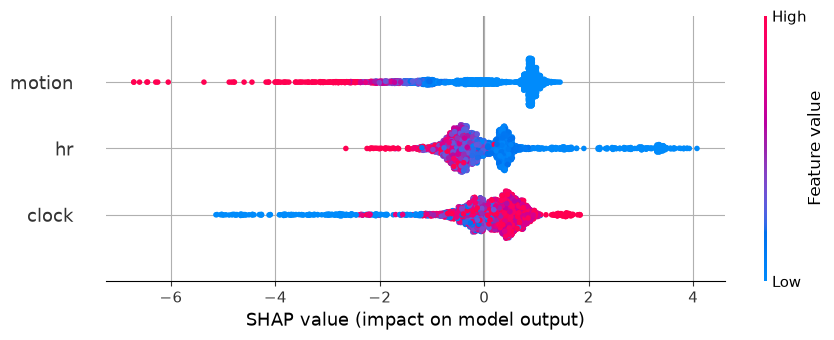

In [9]:
import lightgbm as lgb, shap
X, ys, _ = sl.stack(data, sl.SUBJECTS, F)
m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=50, verbose=-1).fit(X, sl.sleep_wake(ys))
idx = np.random.default_rng(0).choice(len(X), 3000, replace=False)
sv = shap.TreeExplainer(m).shap_values(X[idx])
shap.summary_plot(sv, X[idx], feature_names=F, plot_size=(9, 3.5))